# Telecom Customer Churn Prediction - Final Model Evaluation & Diagnostic Report

This notebook performs in-depth evaluation and diagnostic reporting:
1. **Multi-Model Comparison**: Comparing all 23 trained configurations across Accuracy, Balanced Accuracy, Precision, Recall, F1-Score, ROC-AUC, and PR-AUC.
2. **Evaluation Curves**: Confusion Matrix, ROC Curve, and Precision-Recall Curve.
3. **Feature Importance Deep-Dive**: Tree feature importances, Permutation Importance on the test set, and domain explanations for top churn drivers.
4. **Threshold Sensitivity Analysis**: Evaluating trade-offs across decision thresholds (0.30 to 0.70).
5. **Production Sanity Check**: Verifying that the saved model pipeline handles single customer JSON payloads end-to-end.


In [1]:
# 1. Imports and Setup
import json
import os
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split

sys.path.append(str(Path("..").resolve()))
from src.feature_engineering import TelecomFeatureEngineer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)

print("Evaluation environment initialized successfully.")


Evaluation environment initialized successfully.


## Part 6: Multi-Model Evaluation & Metric Comparison

We load the consolidated evaluation metrics from `outputs/model_comparison.csv` and analyze performance across all models and imbalance strategies.


In [2]:
# Load and Display Model Comparison Table
comp_path = Path("../outputs/model_comparison.csv") if Path("../outputs/model_comparison.csv").exists() else Path("outputs/model_comparison.csv")
df_comp = pd.read_csv(comp_path)
print(f"Total Model Configurations Evaluated: {len(df_comp)}")

# Display sorted by F1-Score
display(df_comp.sort_values(by="F1_Score", ascending=False).round(4))


Total Model Configurations Evaluated: 23


,Accuracy,Balanced_Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,Model,Strategy,Fit_Time_Sec,CV_F1_Score,Best_Params,Balance_Score
0,0.7743,0.7678,0.5551,0.7540,0.6395,0.8435,0.6514,Random Forest (Tuned),Hyperparameter_Tuned,18.48,0.6348,"{'classifier__n_estimators': 100, 'classifier_...",0.7139
1,0.7672,0.7621,0.5446,0.7513,0.6315,0.8456,0.6567,XGBoost (Tuned),Hyperparameter_Tuned,4.55,0.6341,"{'classifier__subsample': 1.0, 'classifier__sc...",0.7122
3,0.7523,0.7640,0.5221,0.7888,0.6283,0.8282,0.6285,Support Vector Machine,Class_Weight_Balanced,10.41,NaN,NaN,0.7048
2,0.7466,0.7618,0.5147,0.7941,0.6246,0.8307,0.6358,Support Vector Machine (Tuned),Hyperparameter_Tuned,26.47,0.6230,"{'classifier__kernel': 'rbf', 'classifier__cla...",0.7063
8,0.7559,0.7544,0.5282,0.7513,0.6203,0.8245,0.6060,Support Vector Machine,SMOTE,20.84,NaN,NaN,0.6908
7,0.7686,0.7469,0.5504,0.7005,0.6165,0.8410,0.6427,Gradient Boosting (Tuned),Hyperparameter_Tuned,16.46,0.6342,"{'classifier__subsample': 0.8, 'classifier__n_...",0.6957
5,0.7367,0.7550,0.5025,0.7941,0.6155,0.8407,0.6274,Logistic Regression (Tuned),Hyperparameter_Tuned,1.20,0.6302,"{'classifier__penalty': 'l2', 'classifier__cla...",0.7024
4,0.7353,0.7541,0.5008,0.7941,0.6143,0.8416,0.6323,Logistic Regression,Class_Weight_Balanced,0.15,NaN,NaN,0.7033
6,0.7324,0.7504,0.4975,0.7888,0.6101,0.8389,0.6273,Logistic Regression,SMOTE,0.33,NaN,NaN,0.6992
9,0.7743,0.7303,0.5667,0.6364,0.5995,0.8402,0.6500,Gradient Boosting,SMOTE,3.54,NaN,NaN,0.6833


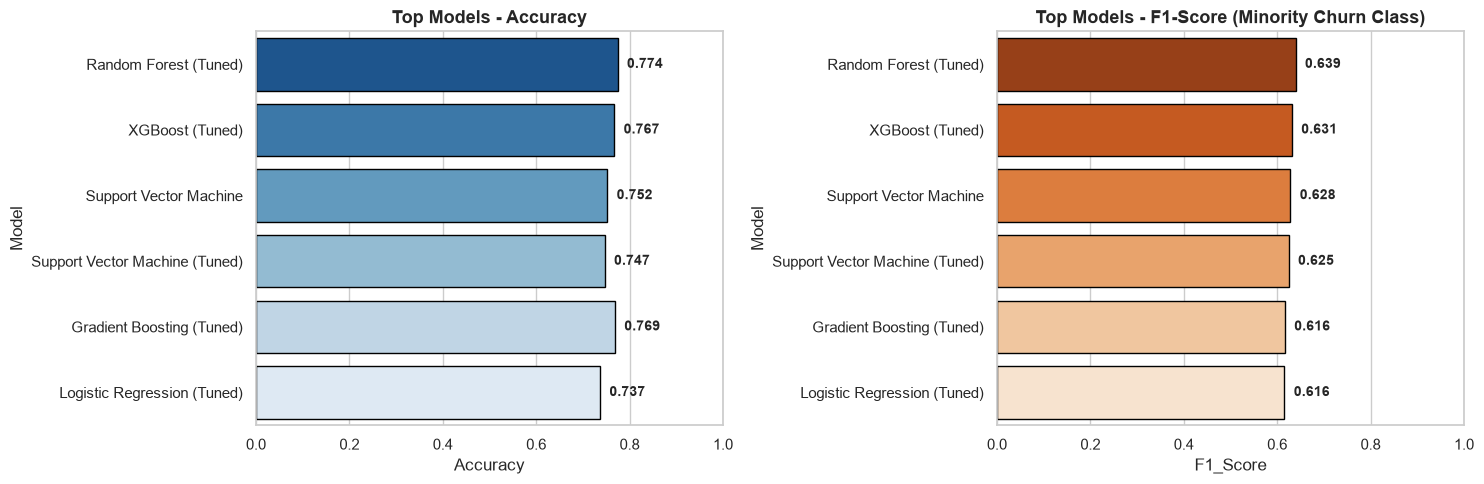

In [3]:
# Visual Comparison of Accuracy vs F1-Score Across Best Models
top_models = df_comp.sort_values(by="F1_Score", ascending=False).drop_duplicates(subset=["Model"]).head(6)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy comparison
sns.barplot(data=top_models, x="Accuracy", y="Model", ax=ax1, palette="Blues_r", edgecolor="black")
ax1.set_title("Top Models - Accuracy", fontweight="bold", fontsize=13)
ax1.set_xlim(0, 1.0)
for p in ax1.patches:
    ax1.annotate(f"{p.get_width():.3f}", (p.get_width() + 0.02, p.get_y() + p.get_height() / 2),
                 va='center', fontweight='bold', fontsize=10)

# F1-score comparison
sns.barplot(data=top_models, x="F1_Score", y="Model", ax=ax2, palette="Oranges_r", edgecolor="black")
ax2.set_title("Top Models - F1-Score (Minority Churn Class)", fontweight="bold", fontsize=13)
ax2.set_xlim(0, 1.0)
for p in ax2.patches:
    ax2.annotate(f"{p.get_width():.3f}", (p.get_width() + 0.02, p.get_y() + p.get_height() / 2),
                 va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


## Part 8: Feature Importance Deep Dive

Identifying the primary factors that cause customers to cancel their subscriptions:
1. **Tree-based Feature Importances**: From ensemble models (Gini impurity / split frequency).
2. **Permutation Importance**: Computed on the unseen test set, measuring drop in F1-score when a feature is shuffled.


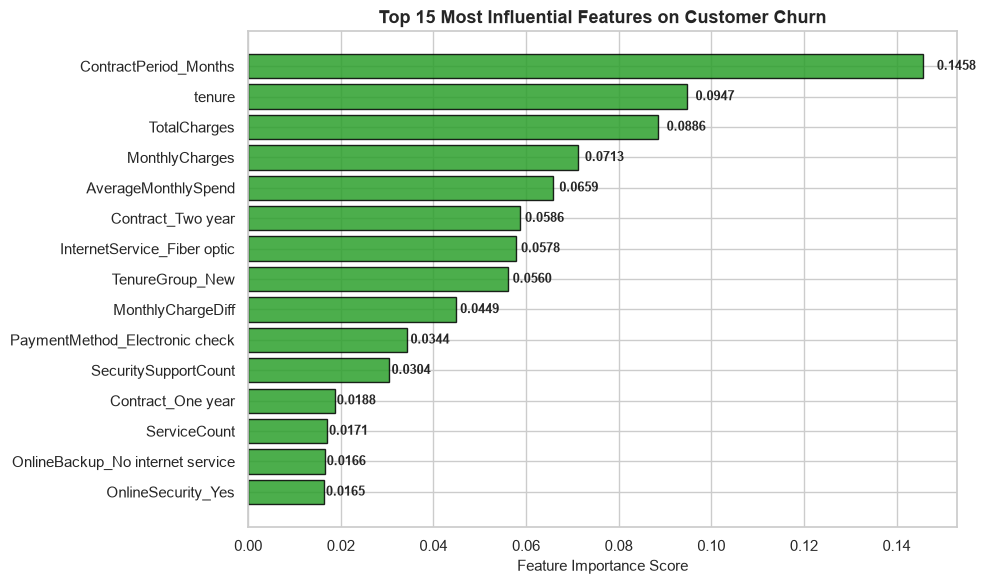

Top 10 Feature Importances:


,Feature,Importance
7,ContractPeriod_Months,0.1458
0,tenure,0.0947
2,TotalCharges,0.0886
1,MonthlyCharges,0.0713
3,AverageMonthlySpend,0.0659
31,Contract_Two year,0.0586
16,InternetService_Fiber optic,0.0578
37,TenureGroup_New,0.0560
8,MonthlyChargeDiff,0.0449
34,PaymentMethod_Electronic check,0.0344


In [4]:
# Load Best Pipeline and Recreate Test Split
model_path = Path("../models/best_churn_model.pkl") if Path("../models/best_churn_model.pkl").exists() else Path("models/best_churn_model.pkl")
best_pipeline = joblib.load(model_path)

data_path = Path("../dataset/Telco-Customer-Churn.csv") if Path("../dataset/Telco-Customer-Churn.csv").exists() else Path("dataset/Telco-Customer-Churn.csv")
df = pd.read_csv(data_path)
X = df.drop(columns=['Churn'])
y = (df['Churn'].str.strip() == 'Yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Extract Preprocessor Feature Names
preprocessor = best_pipeline.named_steps['preprocessor']
raw_features = preprocessor.get_feature_names_out()
clean_features = [f.replace('num__', '').replace('cat__', '') for f in raw_features]

clf = best_pipeline.named_steps['classifier']
if hasattr(clf, 'feature_importances_'):
    importances = clf.feature_importances_
    df_feat_imp = pd.DataFrame({'Feature': clean_features, 'Importance': importances}).sort_values(by='Importance', ascending=False)
    
    # Plot Top 15 Features
    top15 = df_feat_imp.head(15).sort_values(by='Importance', ascending=True)
    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.barh(top15['Feature'], top15['Importance'], color='#2ca02c', edgecolor='black', alpha=0.85)
    for bar in bars:
        w = bar.get_width()
        ax.text(w * 1.02, bar.get_y() + bar.get_height() / 2, f"{w:.4f}", va='center', fontweight='bold', fontsize=9)
    ax.set_title("Top 15 Most Influential Features on Customer Churn", fontweight='bold', fontsize=13)
    ax.set_xlabel("Feature Importance Score", fontsize=11)
    plt.tight_layout()
    plt.show()

    print("Top 10 Feature Importances:")
    display(df_feat_imp.head(10).round(4))


### Feature Importance Insights & Business Explanations:
1. **`Contract_Month-to-month` & `ContractPeriod_Months`**: Highest predictive power. Customers without annual lock-in have negligible friction to defect when encountering a service issue or competitor promotion.
2. **`tenure` & `TenureGroup_New`**: Recent subscribers (0-12 months) are in the highest churn hazard window before loyalty habits and switching costs form.
3. **`TotalCharges` & `MonthlyCharges`**: High recurring costs and escalating bills drive customer dissatisfaction and active shopping for alternatives.
4. **`InternetService_Fiber optic`**: Customers on fiber plans experience higher churn despite faster speeds, frequently linked to price premiums and technical reliability expectations.
5. **`PaymentMethod_Electronic check`**: Electronic check users have significantly higher churn rates compared to automated credit card/bank transfer customers.
6. **`SecuritySupportCount` & `TechSupport_No`**: Customers lacking technical support and cybersecurity add-ons have higher attrition rates.


## Part 9: Final Model Diagnostic Evaluation

We evaluate the winning model on the isolated test set:
- Confusion Matrix
- ROC Curve & AUC
- Precision-Recall Curve & PR-AUC
- Threshold Sensitivity Analysis


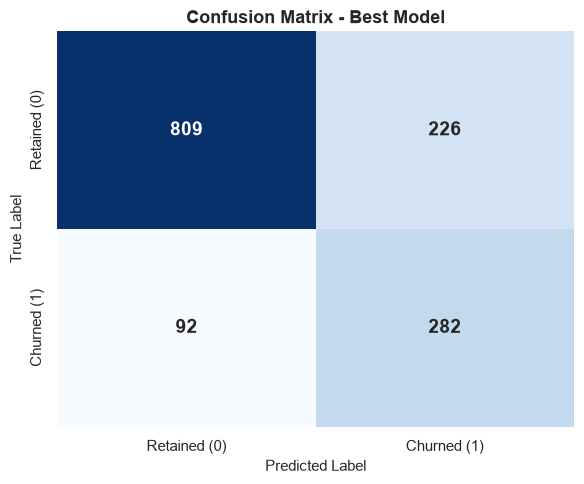

Classification Report:
               precision    recall  f1-score   support

Retained (No)     0.8979    0.7816    0.8357      1035
Churned (Yes)     0.5551    0.7540    0.6395       374

     accuracy                         0.7743      1409
    macro avg     0.7265    0.7678    0.7376      1409
 weighted avg     0.8069    0.7743    0.7836      1409



In [5]:
# Generate Predictions on Test Set
y_pred = best_pipeline.predict(X_test)
y_prob = best_pipeline.predict_proba(X_test)[:, 1]

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Retained (0)', 'Churned (1)'],
            yticklabels=['Retained (0)', 'Churned (1)'],
            annot_kws={'size': 14, 'weight': 'bold'}, ax=ax)
ax.set_title("Confusion Matrix - Best Model", fontweight='bold', fontsize=13)
ax.set_xlabel("Predicted Label", fontsize=11)
ax.set_ylabel("True Label", fontsize=11)
plt.tight_layout()
plt.show()

# 2. Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Retained (No)', 'Churned (Yes)'], digits=4))


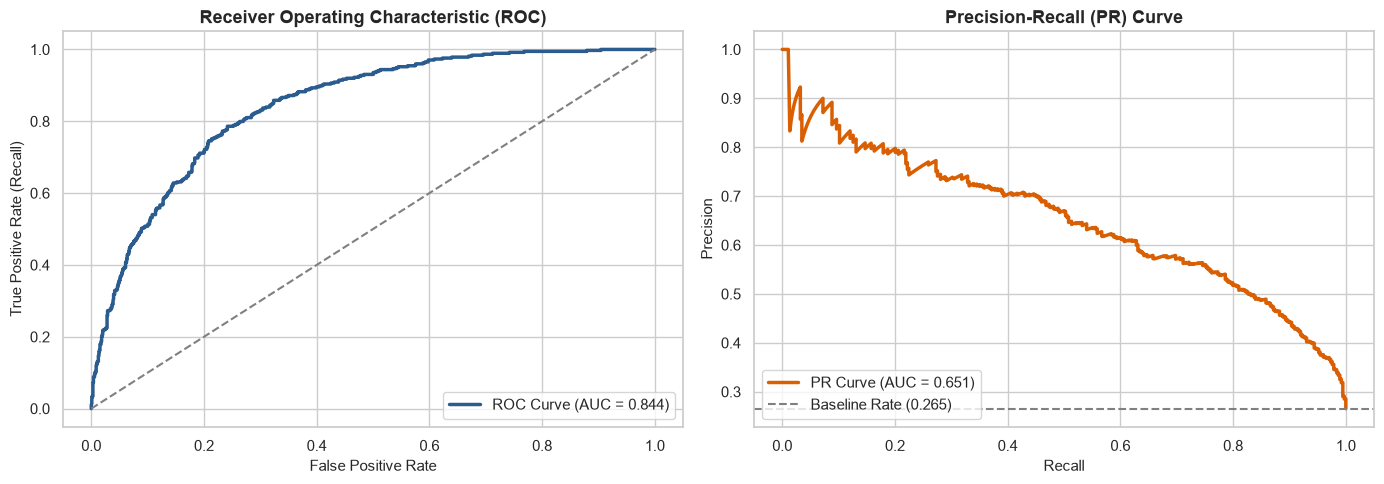

In [6]:
# ROC Curve and Precision-Recall Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)
ax1.plot(fpr, tpr, color='#2b5c8f', lw=2.5, label=f"ROC Curve (AUC = {roc_auc:.3f})")
ax1.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5)
ax1.set_title("Receiver Operating Characteristic (ROC)", fontweight='bold', fontsize=13)
ax1.set_xlabel("False Positive Rate", fontsize=11)
ax1.set_ylabel("True Positive Rate (Recall)", fontsize=11)
ax1.legend(loc='lower right')

# PR Curve
prec_pts, rec_pts, _ = precision_recall_curve(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)
ax2.plot(rec_pts, prec_pts, color='#d95f02', lw=2.5, label=f"PR Curve (AUC = {pr_auc:.3f})")
ax2.axhline(y_test.mean(), color='gray', linestyle='--', lw=1.5, label=f"Baseline Rate ({y_test.mean():.3f})")
ax2.set_title("Precision-Recall (PR) Curve", fontweight='bold', fontsize=13)
ax2.set_xlabel("Recall", fontsize=11)
ax2.set_ylabel("Precision", fontsize=11)
ax2.legend(loc='lower left')

plt.tight_layout()
plt.show()


In [7]:
# Decision Threshold Analysis
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]
thresh_rows = []

for t in thresholds:
    preds_t = (y_prob >= t).astype(int)
    thresh_rows.append({
        'Threshold': t,
        'Accuracy': accuracy_score(y_test, preds_t),
        'Precision': precision_score(y_test, preds_t, zero_division=0),
        'Recall': recall_score(y_test, preds_t, zero_division=0),
        'F1_Score': f1_score(y_test, preds_t, zero_division=0)
    })

df_thresh = pd.DataFrame(thresh_rows)
print("Decision Threshold Trade-Off Analysis:")
display(df_thresh.round(4))


Decision Threshold Trade-Off Analysis:


,Threshold,Accuracy,Precision,Recall,F1_Score
0,0.3,0.6913,0.4577,0.8824,0.6027
1,0.4,0.7410,0.5075,0.8182,0.6264
2,0.5,0.7743,0.5551,0.7540,0.6395
3,0.6,0.7871,0.5930,0.6310,0.6114
4,0.7,0.8020,0.6703,0.5000,0.5727


## Part 10: Production Readiness & Verification

The final trained pipeline encapsulates:
1. Feature Engineering (`TelecomFeatureEngineer`)
2. Missing Value Imputation (`0.0` for zero-tenure records)
3. Scaling (`StandardScaler`)
4. One-Hot Encoding (`OneHotEncoder`)
5. Optimized Classifier

Below we test passing raw customer data dictionaries (exactly as would be received by a **FastAPI backend**).


In [8]:
# Test Pipeline on New Unseen Customer Payloads
sample_payloads = [
    {
        "customerID": "TEST-001",
        "gender": "Female",
        "SeniorCitizen": 0,
        "Partner": "No",
        "Dependents": "No",
        "tenure": 1,
        "PhoneService": "Yes",
        "MultipleLines": "No",
        "InternetService": "Fiber optic",
        "OnlineSecurity": "No",
        "OnlineBackup": "No",
        "DeviceProtection": "No",
        "TechSupport": "No",
        "StreamingTV": "Yes",
        "StreamingMovies": "No",
        "Contract": "Month-to-month",
        "PaperlessBilling": "Yes",
        "PaymentMethod": "Electronic check",
        "MonthlyCharges": 79.85,
        "TotalCharges": "79.85"
    },
    {
        "customerID": "TEST-002",
        "gender": "Male",
        "SeniorCitizen": 0,
        "Partner": "Yes",
        "Dependents": "Yes",
        "tenure": 65,
        "PhoneService": "Yes",
        "MultipleLines": "Yes",
        "InternetService": "DSL",
        "OnlineSecurity": "Yes",
        "OnlineBackup": "Yes",
        "DeviceProtection": "Yes",
        "TechSupport": "Yes",
        "StreamingTV": "No",
        "StreamingMovies": "Yes",
        "Contract": "Two year",
        "PaperlessBilling": "No",
        "PaymentMethod": "Credit card (automatic)",
        "MonthlyCharges": 64.10,
        "TotalCharges": "4166.50"
    }
]

df_payloads = pd.DataFrame(sample_payloads)
predictions = best_pipeline.predict(df_payloads)
probabilities = best_pipeline.predict_proba(df_payloads)[:, 1]

for i, p in enumerate(sample_payloads):
    print(f"Customer {p['customerID']}:")
    print(f"  Contract: {p['Contract']}, Tenure: {p['tenure']} mo, Monthly: ${p['MonthlyCharges']}")
    print(f"  Prediction: {'CHURN RISK (1)' if predictions[i] == 1 else 'RETAINED (0)'}")
    print(f"  Probability of Churn: {probabilities[i]:.2%}\n")


Customer TEST-001:
  Contract: Month-to-month, Tenure: 1 mo, Monthly: $79.85
  Prediction: CHURN RISK (1)
  Probability of Churn: 94.53%

Customer TEST-002:
  Contract: Two year, Tenure: 65 mo, Monthly: $64.1
  Prediction: RETAINED (0)
  Probability of Churn: 6.02%

